# Basic Stats II: Distributions and Estimators

G. Richards
(2016, 2018, 2020, 2022, 2024)

Resources for this material include Ivezic Sections 3.3-3.5, Karen' Leighly's [Bayesian Statistics Lecture](http://seminar.ouml.org/lectures/bayesian-statistics/), and [Bevington's book](https://experimentationlab.berkeley.edu/sites/default/files/pdfs/Bevington.pdf).   With updates to my own class from [Stephen Taylor's class at Vanderbilt](https://github.com/VanderbiltAstronomy/astr_8070_s24) (which covers this material in their Lectures 2-4).

#### Reading:

- [Textbook](http://press.princeton.edu/titles/10159.html) Chapter 3.

## Contents
* [Uniform Distribution](#one)
* [Gaussian Distribution](#two)
* [Gaussian Confidence Levels](#three)
* [Log Normal Distribution](#four)
* [$\chi^2$ Distribution](#five)
* [Students' $t$ Distribution](#six)
* [Central Limit Theorem](#seven)
* [Bivariate and Multivariate Distribution Functions](#eight)

This material is at the end of Vanderbilt's Lecture 3

## Distributions

If we are attempting to characterize our data in a way that is **parameterized**, then we need a functional form or a **distribution**.  There are many naturally occurring distributions.  The book goes through quite a few of them.  Here we'll just talk about a few basic ones to get us started.


### Uniform Distribution <a class="anchor" id="one"></a>

The uniform distribution is perhaps more commonly called a "top-hat" or a "box" distribution.  It is specified by a mean, $\mu$, and a width, $W$, where

$$p(x|\mu,W) = \frac{1}{W}$$

over the range $|x-\mu|\le \frac{W}{2}$ and $0$ otherwise.  That says that "given $\mu$ AND $W$, the probability of $x$ is $\frac{1}{W}$" (as long as we are within a certain range).

Since we are used to thinking of a Gaussian as the *only* type of distribution the concept of $\sigma$ (aside from the width) may seem strange.  But $\sigma$ as mathematically defined last time applies here and is
$$\sigma = \frac{W}{\sqrt{12}}.$$


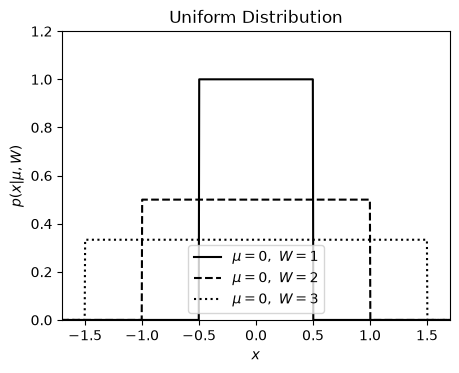

In [1]:
# Execute this cell
# Since you're working with a copy of my notebook, you 
# may need to change the path below to find the file
%run fig_uniform_distribution.py

We can implement [uniform](http://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.uniform.html#scipy.stats.uniform) in `scipy` as follows.  We'll use the methods listed at the bottom of the link to complete the cell: `dist.rvs(size=N)` which produces `N` random draws from the distribution and `dist.pdf(x)` which returns the value of the pdf at a given $x$.  Lots of distributions can be accessed and used in a similar way. 

<font color='red'>First create a uniform distribution with parameters `loc=0`, `scale=2`, and `N=10`.  Complete and execute the following cell.</font>

In [10]:
# Complete and execute this cell
from scipy import stats
import numpy as np
N = 10 #Complete
distU = stats.uniform(0, 3) #Complete
draws = distU.rvs(size=10) # ten random draws
print(draws)
p = distU.pdf(x=1) #pdf evaluated at x=1
print(p)

[2.98430699 2.76139456 0.67329567 0.50170944 0.66570502 0.2504678
 2.12559249 2.79236356 1.99290952 1.7295121 ]
0.3333333333333333


Did you expect that answer for the pdf?  Why?  What would the pdf be if you changed the width to 4?

### Gaussian Distribution <a class="anchor" id="two"></a>

We have already seen that the Gaussian distribution is given by
$$p(x|\mu,\sigma) = \frac{1}{\sigma\sqrt{2\pi}} \exp\left(\frac{-(x-\mu)^2}{2\sigma^2}\right).$$

It is also called the **normal distribution** and can be noted by $\mathscr{N}(\mu,\sigma)$.


We frequently use Gaussians in physics and astronomy because they can approximate many distributions and are relatively easy to work with. Note that **the convolution of two Gaussians results in a Gaussian.**  So $\mathscr{N}(\mu_1,\sigma_1)$ convolved with $\mathscr{N}(\mu_2,\sigma_2)$ is $\mathscr{N}(\mu_1+\mu_2,\sqrt{\sigma_1^2+\sigma_2^2})$.

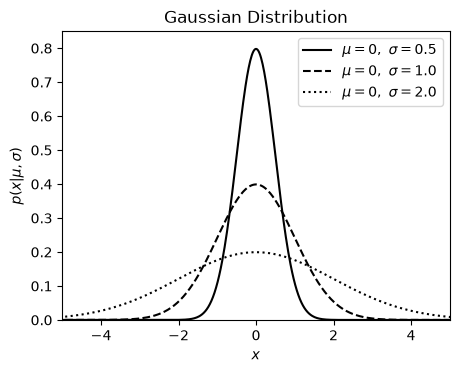

In [6]:
# Execute this cell
%run fig_gaussian_distribution.py

In [ ]:
# %load fig_gaussian_distribution.py
"""
Example of a Gaussian distribution
----------------------------------
Figure 3.8.

This shows an example of a gaussian distribution with various parameters.
We'll generate the distribution using::

    dist = scipy.stats.norm(...)

Where ... should be filled in with the desired distribution parameters
Once we have defined the distribution parameters in this way, these
distribution objects have many useful methods; for example:

* ``dist.pmf(x)`` computes the Probability Mass Function at values ``x``
  in the case of discrete distributions

* ``dist.pdf(x)`` computes the Probability Density Function at values ``x``
  in the case of continuous distributions

* ``dist.rvs(N)`` computes ``N`` random variables distributed according
  to the given distribution

Many further options exist; refer to the documentation of ``scipy.stats``
for more details.
"""
# Author: Jake VanderPlas
# License: BSD
#   The figure produced by this code is published in the textbook
#   "Statistics, Data Mining, and Machine Learning in Astronomy" (2013)
#   For more information, see http://astroML.github.com
#   To report a bug or issue, use the following forum:
#    https://groups.google.com/forum/#!forum/astroml-general
import numpy as np
from scipy.stats import norm
from matplotlib import pyplot as plt

#----------------------------------------------------------------------
# This function adjusts matplotlib settings for a uniform feel in the textbook.
# Note that with usetex=True, fonts are rendered with LaTeX.  This may
# result in an error if LaTeX is not installed on your system.  In that case,
# you can set usetex to False.
#from astroML.plotting import setup_text_plots
#setup_text_plots(fontsize=8, usetex=True)

#------------------------------------------------------------
# Define the distributions to be plotted
sigma_values = [0.5, 1.0, 2.0]
linestyles = ['-', '--', ':']
mu = 0
x = np.linspace(-10, 10, 1000)

#------------------------------------------------------------
# plot the distributions
fig, ax = plt.subplots(figsize=(5, 3.75))

for sigma, ls in zip(sigma_values, linestyles):
    # create a gaussian / normal distribution
    dist = norm(mu, sigma)

    plt.plot(x, dist.pdf(x), ls=ls, c='black',
             label=r'$\mu=%i,\ \sigma=%.1f$' % (mu, sigma))

plt.xlim(-5, 5)
plt.ylim(0, 0.85)

plt.xlabel('$x$')
plt.ylabel(r'$p(x|\mu,\sigma)$')
plt.title('Gaussian Distribution')

plt.legend()
plt.show()


Let's get some practice!  See http://www.astroml.org/book_figures/chapter3/fig_gaussian_distribution.html

In the same manner as above, create a [normal distribution](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html?highlight=stats%20norm#scipy.stats.norm) with `loc=100` and `scale=15`.  Produce 10 random draws and determine the probability at `x=145`.

This will be helpful to us in our later example with IQ tests, since IQ is distributed (by definition) 
as $\mathscr{N}$(mu=100,sigma=15)

<font color='red'>Complete and execute the following cell.</font>

In [13]:
# Complete and execute this cell
mu = 100 
sigma = 15
distG = stats.norm(mu, sigma) # Normal distribution with mean = 100, stdev = 15
draws = distG.rvs(10) # 10 random draws
p = distG.pdf(100) # pdf evaluated at x=100
print(draws)
print(p)

[ 77.46118283 102.72772088 101.40454674 142.24586753 125.15712885
 100.47148535 123.34079693 103.11097007 126.069299   112.34174525]
0.02659615202676218


Make a plot of this Gaussian distribution. Plot the pdf from 0 to 200 with a 1000 gridpoints.  

<font color='red'>Complete and execute the following cell.</font>

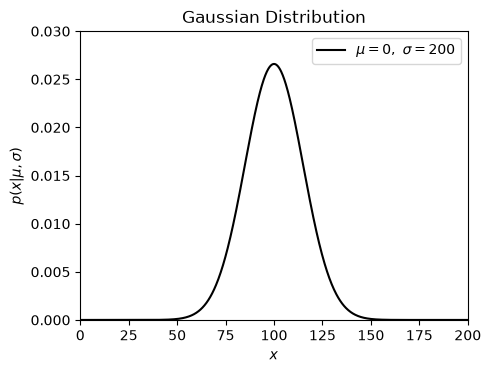

In [16]:
## Let's play with Gaussians! Or Normal distributions, N(mu,sigma)
## see http://www.astroml.org/book_figures/chapter3/fig_gaussian_distribution.html
## Example: IQ is (by definition) distributed as N(mu=100,sigma=15)

mu = 0
sigma = 200

xgrid = np.linspace(0, 200, 1000) # generate distribution for a uniform grid of x values
gaussPDF = distG.pdf(xgrid)  # this is a function of xgrid

# actual plotting
fig, ax = plt.subplots(figsize=(5, 3.75))
plt.plot(xgrid, gaussPDF, ls='-', c='black', label=r'$\mu=%i,\ \sigma=%i$' % (mu, sigma))
plt.xlim(0, 200)
plt.ylim(0, 0.03)
plt.xlabel('$x$')
plt.ylabel(r'$p(x|\mu,\sigma)$')
plt.title('Gaussian Distribution')
plt.legend()

Above we plotted probability density function.  Sometimes what you want instead is the cumulative distribution function, cdf.  The CDF is the integral of pdf from $x'=-\infty$ to $x'=x$:
$${\rm CDF}(x|\mu,\sigma) = \int_{-\infty}^{x'} p(x'|\mu,\sigma) dx',$$
where
${\rm CDF}(\infty) = 1$.

You will get some practice with CDFs in the homework assignment.

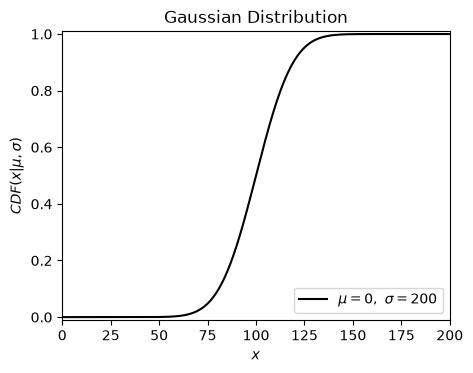

In [17]:
#The same as above but now with the cdf method
gaussCDF = distG.cdf(xgrid)
fig, ax = plt.subplots(figsize=(5, 3.75))
plt.plot(xgrid, gaussCDF, ls='-', c='black', label=r'$\mu=%i,\ \sigma=%i$' % (mu, sigma))
plt.xlim(0, 200)
plt.ylim(-0.01, 1.01)
plt.xlabel('$x$')
plt.ylabel(r'$CDF(x|\mu,\sigma)$')
plt.title('Gaussian Distribution')
plt.legend(loc=4)

## Gaussian confidence levels  <a class="anchor" id="three"></a>

The probability of a measurement drawn from a Gaussian distribution that is between $\mu-a$ and $\mu+b$ is
$$\int_{\mu-a}^{\mu+b} p(x|\mu,\sigma) dx.$$

* For $a=b=1\sigma$, we get the familar result of 68.3%.  
* For $a=b=2\sigma$ it is 95.4%.  
* For $a=b=3\sigma$ it is $99.7\%$. 

So we refer to the range $\mu \pm 1\sigma$, $\mu \pm 2\sigma$, and $\mu \pm 3\sigma$ as the 68%, 95%, and 99% **confidence limits**, respectively. Note that if your distribution is not Gaussian, then these confidence intervals will be different!

***We often still refer to uncertainty regions of distributions as $1\sigma$ or $2\sigma$ regions, which for non-Gaussian distributions usually means (for $1\sigma$) the region enclosing the $16\%$ and $84\%$ quantiles.***

Can you figure out what the probability is for $-2\sigma, +4\sigma$?  Check to see that you get the right answer for the cases above first!

<font color='red'>Complete and execute the following cell</font>

In [20]:
# Complete and execute this cell
N=10000
mu=0
sigma=1
distN = stats.norm(mu, sigma) # Complete
xgrid = np.linspace(-2*sigma, 4*sigma, N) # Complete
dx = (xgrid.max()-xgrid.min())/N
prob = distN.pdf(xgrid)*dx
print(prob.sum())

0.9771367091734853


We could do this a number of different ways.   I did it this way so that we could see what is going on.  Basically using the trapezoidal method, computing the height and the width and summing them up.  But the clever way is to use the cdf, by computing the cdf of the upper integration bound and subtracting the cdf of the lower integration bound.

In [21]:
upper = distN.cdf(4) #Complete
lower = distN.cdf(-2)
p = upper-lower
print(p)

0.9772181968099877


You'll get some practice with this in a Data Camp lesson next week (after we talk about Bootstrap and Jackknife estimates).

### Log Normal  <a class="anchor" id="four"></a>

If $x$ is Gaussian distributed with $\mathscr{N}(\mu,\sigma)$, then $y=\exp(x)$ will have a **log-normal** distribution, where the mean of y is $\exp(\mu + \sigma^2/2)$.  Try it.

In [22]:
# Execute this cell
import numpy as np
x = stats.norm(0,1) # mean = 0, stdev = 1
y = np.exp(x.rvs(100))
print(y.mean())
print(x)

1.478398039964807


The catch here is that stats.norm(0,1) returns an *object* and not something that we can just do math on in the expected manner.  What *can* you do with it?  Try ```dir(x)``` to get a list of all the methods and properties.

In [23]:
import math
distLN = stats.norm(0,1) # mean = 0, stdev = 1
x = distLN.rvs(100000)
y = np.exp(x)
print(math.exp(0+1*1/2.0), y.mean())

1.6487212707001282 1.6431097115370787


<font color='red'>Repeat the above calculations to verify the equations for the mode and median.</font>

### $\chi^2$ Distribution  <a class="anchor" id="five"></a>

We'll run into the $\chi^2$ distribution when we talk about Maximum Likelihood in the next chapter.

If we have a Gaussian distribution with values ${x_i}$, and we scale and normalize them according to
$$z_i = \frac{x_i-\mu}{\sigma},$$
then the sum of squares, $Q$ 
$$Q = \sum_{i=1}^N z_i^2,$$
will follow the $\chi^2$ distribution.  The **number of degrees of freedom**, $k$, is given by the number of data points, $N$ (minus any constraints).  The pdf of $Q$ given $k$ defines $\chi^2$ and is given by
$$p(Q|k)\equiv \chi^2(Q|k) = \frac{1}{2^{k/2}\Gamma(k/2)}Q^{k/2-1}\exp(-Q/2).$$
where $Q>0$ and the $\Gamma$ function would just be the usual factorial function if we were dealing with integers, but here we have half integers.

This is ugly, but it is really just a formula like anything else.  Note that the shape of the distribution *only* depends on the sample size $N=k$ and not on $\mu$ or $\sigma$.  

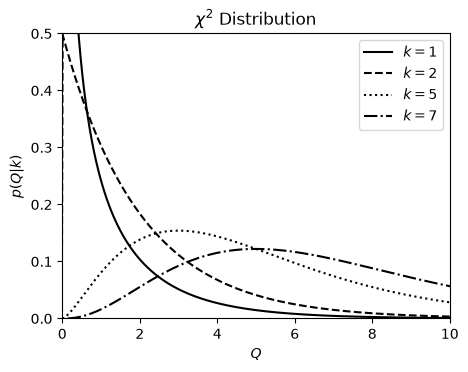

In [24]:
# Execute this cell
%run fig_chi2_distribution.py

### Chi-squared per degree of freedom

In practice we frequently divide $\chi^2$ by the number of degrees of freedom, and work with:

$$\chi^2_{dof} = \frac{1}{N-1} \sum_{i=1}^N \left(\frac{x_i-\overline{x}}{\sigma}\right)^2$$

which (for large $k$) is distributed as

$$ p(\chi^2_{dof}) \sim \mathscr{N}\left(1, \sqrt{\frac{2}{N-1}}\right) $$

(where $k = N-1$, and $N$ is the number of samples). Therefore, we expect $\chi^2_{dof}$ to be 1, to within a few $\sqrt{\frac{2}{N-1}}$.

See the [Khan Academy's chi-square distribution introduction](https://www.khanacademy.org/math/statistics-probability/inference-categorical-data-chi-square-tests/chi-square-goodness-of-fit-tests/v/chi-square-distribution-introduction), which is actually somewhat confusing but shows how to use probability tables (starting at 7:50) to get so-called $p$-values.

If you are so inclined, you could look ahead to next week a bit and watch the video on Least-squares regression
https://www.khanacademy.org/math/statistics-probability/describing-relationships-quantitative-data/regression-library/v/introduction-to-residuals-and-least-squares-regression

### Poisson distribution

This is a distribution for a discrete variable, telling you the probability of $k$ events occuring within a certain time when the mean is $\mu$:

$$ p(k|\mu) = \frac{\mu^k \exp(-\mu)}{k!} $$

where the mean $\mu$ completely characterizes the distribution. The mode is $(\mu-1)$, the standard deviation is $\sqrt{\mu}$, the skewness is $1/\sqrt{\mu}$, and the kurtosis is $1/\mu$.

As $\mu$ increases the Poisson distribution becomes more and more similar to a Gaussian with $\mathcal{N}(\mu,\sqrt{\mu})$. The Poisson distribution is sometimes called the ***law of small numbers*** or ***law of rare events***.

<font color='red'>Complete and execute the following cell for $\mu=3$.</font>

In [30]:
# Practice the Poisson distribution
mu = 3
dist = stats.poisson(mu)

k = dist.rvs(20) # make 20 draws
pmf = dist.pmf(6) # evaluate probability mass function at 6
print(pmf)

0.05040940672246224


### Student's $t$ Distribution  <a class="anchor" id="six"></a>

Another distribution that we'll see later is the Student's $t$ Distribution.

If you have a sample of $N$ measurements, $\{x_i\}$, drawn from a Gaussian distribution, $\mathscr{N}(\mu,\sigma)$, and you apply the transform
$$t = \frac{\overline{x}-\mu}{s/\sqrt{N}},$$
then $t$ will be distributed according to Student's $t$ with the following pdf (for $k$ degrees of freedom): 
$$p(x|k) = \frac{\Gamma(\frac{k+1}{2})}{\sqrt{\pi k} \Gamma(\frac{k}{2})} \left(1+\frac{x^2}{k}\right)^{-\frac{k+1}{2}}$$

As with a Gaussian, Student's $t$ is bell shaped, but has "heavier" tails.

Note the similarity between $t$ and $z$ for a Gaussian (as defined in the $\chi^2$ section above), which reflects the difference between data-derived estimates of the mean and standard deviation and their true values.

In fact, although often approximated as a Gaussian distribution, the mean of a sample actually follows a Student's $t$ distribution. This matters when sample sizes are small, but mostly irrelevant for "Big Data" examples.

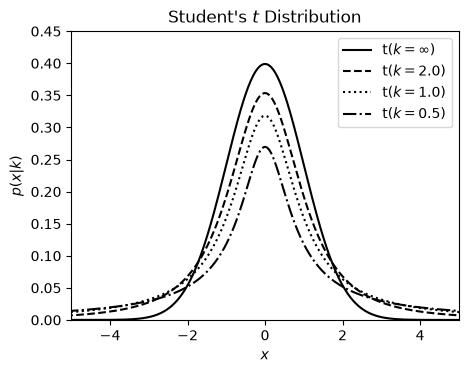

In [31]:
# Execute this cell
%run fig_student_t_distribution.py

Khan Academy on z vs. t statistic:

https://www.google.com/url?client=internal-element-cse&cx=004984196166817161901:gt3nscsxv5o&q=https://www.khanacademy.org/math/statistics-probability/significance-tests-one-sample/more-significance-testing-videos/v/z-statistics-vs-t-statistics&sa=U&ved=2ahUKEwi5we6hkoPsAhWFl3IEHWtUCHYQFjAAegQIABAB&usg=AOvVaw3LYl3JNzQT0qc7ASTt2H90


**FUN FACT:** "Student" was the pen name of W. S. Gosset, who worked for the Guinness brewery in Dublin, Ireland. He was interested in the statistical analysis of small samples, e.g., the chemical properties of barley when the sample size might be as small as $3$.

### What's the point?

* The point is that we are going to make some measurement.  
* To understand the significance of our measurement, we want to know how likely it is that we would get that measurement in our experiment by random chance. 
* To determine that we need to know the shape of the distribution.  Let's say that we find that $x=6$.  If our data is $\chi^2$ distributed with 2 degrees of freedom, then we would integrate the $k=2$ curve above from 6 to $\infty$ to determine how likely it is that we would have gotten 6 or larger by chance.  If our distribution was instead $t$ distributed, we would get a *very* different answer. 

Note that it is important that you decide *ahead of time* what the metric will be for deciding whether this result is significant or not.  More on this later, but see [this article](http://fivethirtyeight.com/features/science-isnt-broken/).

Vanderbilt's Lecture 4 starts here

## Central Limit Theorem  <a class="anchor" id="seven"></a>

One of the reasons that a Gaussian (or Normal) Distribution is so common is because of the **Central Limit Theorem**:

> For an arbitrary distribution, $h(x)$, that has a well-defined mean, $\mu$, and standard deviation, $\sigma$, the mean of $N$ values \{$x_i$\} drawn from the distribution will follow a Gaussian Distribution with $\mathscr{N}(\mu,\sigma/\sqrt{N})$.  (A Cauchy distribution is one example where this fails.)

This theorem is the foundation for performing repeat measurements in order to improve the accuracy of one's experiment. This is truly amazing! No matter what distribution you start off with (provided it has a well defined mean and standard deviation) or the measurement process itself, repeated batches of $N$ draws will follow a Gaussian centered around the mean. 

The **Law of Large Numbers** further says that the sample mean will converge to the distribution mean as $N$ increases.

Personally, I always find this a bit confusing (or at least I forget how it works).  So, let's look at it in detail.

<font color="red">Start by plotting a normal distribution with $\mu=0.5$ and $\sigma=1/\sqrt{12}/\sqrt{2}$.</font>

<font color="red">Then take `N=2` draws using the `np.random.random` distribution and plot them as a rug plot.  Do that a couple of times (e.g., keep hitting Cntrl-Enter in the cell).</font>

Note: Vanderbilt code in Lecture 4 is a little different.

Text(0, 0.5, 'pdf')

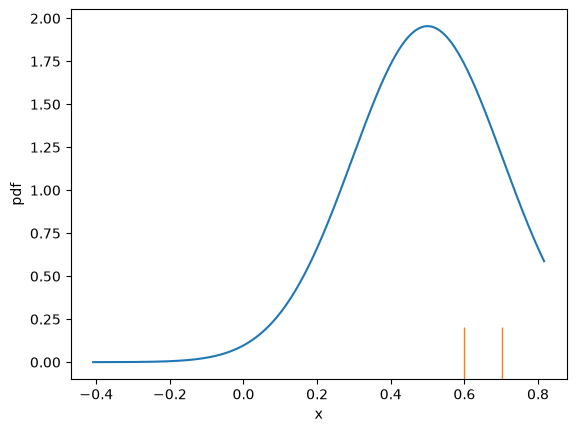

In [34]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.stats import norm

N= 2 # Number of draws
mu= 0.5 # Location
sigma_h =1.0/np.sqrt(12)/np.sqrt(N) # Sqrt(N) properly normalizes the pdf

xgrid = np.linspace(-2*sigma_h,4*sigma_h,1000) # Array to sample the space 
distG = stats.norm(mu,sigma_h) # Complete
plt.plot(xgrid,distG.pdf(xgrid)) # Complete

x = np.random.random(2) # Two random draws (from a Uniform distribution, not a Normal distribution)
plt.plot(x, 0*x, '|', markersize=50)
plt.xlabel('x')
plt.ylabel('pdf')

Now let's average those two draws and plot the result (in the same panel).  Do it as a histogram for 1,000,000 samples (of 2 each).  Use a stepfilled histogram that is normalized with 50% transparency and 100 bins.

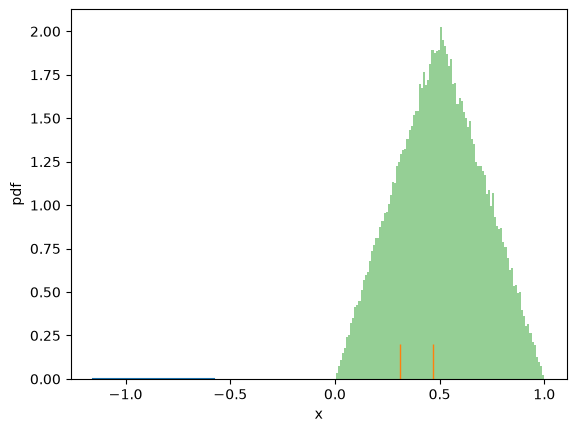

In [38]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.stats import norm

N= 1000000# Number of draws
mu= 0.5 # Location
sigma_h = 1.0 / np.sqrt(12) # scale of h(x)
sigma_cl = sigma_h / np.sqrt(N) # scale of mean error distribution

xgrid = np.linspace(-2*sigma_h,-4*sigma_h, 1000) # Array to sample the space

# plot the distribution of means according to central limit theorem
distG = stats.norm(mu,sigma_cl) # Complete
plt.plot(xgrid,distG.pdf(xgrid)) # Complete

x = np.random.random(2) # N random draws
plt.plot(x, 0*x, '|', markersize=50)
plt.xlabel('x')
plt.ylabel('pdf')

# Add a histogram that is the mean of 1,000,000 draws
yy = []
for i in np.arange(100000):
    xx = np.random.random(2) # N random draws
    yy.append(xx.mean()) # Append average of those random draws to the end of the array

_ = plt.hist(yy,bins=100,histtype='stepfilled', alpha=0.5, density=True)

Now instead of averaging 2 draws, average 3.  Then do it for 10.  Then for 100.  Each time for 1,000,000 samples.


In [ ]:
# Copy your code from above and edit accordingly (or just edit your code from above)

For 100 you will note that your draws are clearly sampling the full range, but the means of those draws are in a *much* more restrictred range.  Moreover they are very closely following a Normal Distribution.  This is the power of the Central Limit Theorem.  Even if you've never heard of or understood the Central Limit Theorem, you probably have been implicitly using it.  We'll see more later when we talk about **maximum likelihood**.

By the way, if your code is ugly, you can run the following cell to reproduce Ivezic, Figure 3.20 which nicely illustrates this in one plot.

In [ ]:
%run ../code/fig_central_limit.py

If you are confused, then watch this video from the Khan Academy:
[https://www.khanacademy.org/math/statistics-probability/sampling-distributions-library/sample-means/v/central-limit-theorem](https://www.khanacademy.org/math/statistics-probability/sampling-distributions-library/sample-means/v/central-limit-theorem)

## Bivariate and Multivariate Distribution Functions  <a class="anchor" id="eight"></a>

Up to now we have been dealing with one-dimensional distribution functions.  Let's now consider a two dimensional distribution $h(x,y)$ where $$\int_{-\infty}^{\infty}dx\int_{-\infty}^{\infty}h(x,y)dy = 1.$$  $h(x,y)$ is telling us the probability that $x$ is between $x$ and $dx$ and *also* that $y$ is between $y$ and $dy$.

Then we have the following definitions:

$$\sigma^2_x = \int_{-\infty}^{\infty}\int_{-\infty}^{\infty}(x-\mu_x)^2 h(x,y) dx dy$$

$$\sigma^2_y = \int_{-\infty}^{\infty}\int_{-\infty}^{\infty}(y-\mu_y)^2 h(x,y) dx dy$$

$$\mu_x = \int_{-\infty}^{\infty}\int_{-\infty}^{\infty}x h(x,y) dx dy$$

$$\sigma_{xy} = Cov(x,y) = \int_{-\infty}^{\infty}\int_{-\infty}^{\infty}(x-\mu_x) (y-\mu_y) h(x,y) dx dy$$

If $x$ and $y$ are uncorrelated, then we can treat the system as two independent 1-D distributions.  This means that choosing a range on one variable has no effect on the distribution of the other.

We can write a 2-D Gaussian pdf as
$$p(x,y|\mu_x,\mu_y,\sigma_x,\sigma_y,\sigma_{xy}) = \frac{1}{2\pi \sigma_x \sigma_y \sqrt{1-\rho^2}} \exp\left(\frac{-z^2}{2(1-\rho^2)}\right),$$

where $$z^2 = \frac{(x-\mu_x)^2}{\sigma_x^2} + \frac{(y-\mu_y)^2}{\sigma_y^2} - 2\rho\frac{(x-\mu_x)(y-\mu_y)}{\sigma_x\sigma_y},$$

with $$\rho = \frac{\sigma_{xy}}{\sigma_x\sigma_y}$$
as the (dimensionless) **correlation coefficient**.

If $x$ and $y$ are perfectly correlated then $\rho=\pm1$ and if they are uncorrelated, then $\rho=0$.

The pdf is now not a histogram, but rather a series of contours in the $x-y$ plane.   These are centered at $(x=\mu_x, y=\mu_y)$ and are tilted at angle $\alpha$, which is given by
$$\tan(2 \alpha) = 2\rho\frac{\sigma_x\sigma_y}{\sigma_x^2-\sigma_y^2} = 2\frac{\sigma_{xy}}{\sigma_x^2-\sigma_y^2}.$$

For example (Ivezic, Figure 3.22):
![Ivezic, Figure 3.22](http://www.astroml.org/_images/fig_bivariate_gaussian_1.png)

We can define new coordinate axes that are aligned with the minimum and maximum widths of the distribution.  These are called the **principal axes** and are given by
$$P_1 = (x-\mu_x)\cos\alpha + (y-\mu_y)\sin\alpha,$$
and
$$P_2 = -(x-\mu_x)\sin\alpha + (y-\mu_y)\cos\alpha.$$

The widths in this coordinate system are
$$\sigma^2_{1,2} = \frac{\sigma_x^2+\sigma_y^2}{2}\pm\sqrt{\left(\frac{\sigma_x^2-\sigma_y^2}{2}\right)^2 + \sigma^2_{xy}}.$$

Note that the correlation vanishes in this coordinate system (by definition) and the bivariate Gaussian is just a product of two univariate Gaussians.  This concept will be crucial for understanding **Principal Component Analysis (PCA)** when we get to Chapter 7, where PCA extends this idea to even more dimensions.

In the univariate case we used $\overline{x}$ and $s$ to *estimate* $\mu$ and $\sigma$.  In the bivariate case we estimate 5 parameters: $(\overline{x},\overline{y},s_x,s_y,s_{xy})$.  

As with the univariate case, it is important to realize that outliers can bias these estimates and that it may be more appropriate to use the median rather than the mean as a more robust estimator for $\mu_x$ and $\mu_y$.  

Similarly we want robust estimators for the other parameters of the fit.  We won't go into that in detail right now, but see Ivezic, Figure 3.23 for an example:

![Ivezic, Figure 3.23](http://www.astroml.org/_images/fig_robust_pca_1.png)

The non-robust estimates (***dashed lines***) give biased sigma ellipses due to the outliers. The robust estimates (***solid lines***) do much better.

<font color='red'>For an example of how to generate a bivariate distribution and plot confidence contours, read through, understand, and execute the following cell.</font>

In [ ]:
# Base code drawn from Ivezic, Figure 3.22, edited by G. Richards to simplify the example

%matplotlib inline
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.patches import Ellipse
from astroML.stats.random import bivariate_normal
from astroML.stats import fit_bivariate_normal

mux = 0
muy = 0
sigx = 1.0
sigy = 1.0
sigxy = 0.3
#------------------------------------------------------------
# Create 10,000 points from a multivariate normal distribution
mean = [mux, muy]
cov = [[sigx, sigxy], [sigxy, sigy]]
x, y = np.random.multivariate_normal(mean, cov, 10000).T

# Fit those data with a bivariate normal distribution
mean, sigma_x, sigma_y, alpha = fit_bivariate_normal(x,y)

#------------------------------------------------------------
# Plot the results
fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(111)

plt.scatter(x,y,s=2,edgecolor='none')

# draw 1, 2, 3-sigma ellipses over the distribution
for N in (1, 2, 3):
    ax.add_patch(Ellipse(mean, N * sigma_x, N * sigma_y, angle=alpha * 180./np.pi, lw=1, ec='k', fc='none'))

Khan academy hypothesis testing (frequency of ABCD)
https://www.google.com/url?client=internal-element-cse&cx=004984196166817161901:gt3nscsxv5o&q=https://www.khanacademy.org/math/ap-statistics/chi-square-tests/chi-square-goodness-fit/v/chi-square-statistic&sa=U&ved=2ahUKEwjW29PBkIPsAhVPmHIEHSpFC9oQFjAAegQIABAB&usg=AOvVaw28z9qyull52vmT8_Pu30bQ
            
Least squares to get slope, intercept
https://www.google.com/url?client=internal-element-cse&cx=004984196166817161901:gt3nscsxv5o&q=https://www.khanacademy.org/math/statistics-probability/describing-relationships-quantitative-data/more-on-regression/v/squared-error-of-regression-line&sa=U&ved=2ahUKEwiQ3py2kYPsAhXjmXIEHU10D2IQFjAGegQIBhAB&usg=AOvVaw1QTAz9IApFRNRtTaNdayAn

Vanderbilt's Lecture 4 has more here, but we just don't have time!